# Cholera model

Equations follow `SPEC.md` (from the "Updated Eqns" doc). States: $y = [N_{SI}, E, V, K^+_{body}]$.

$$\frac{dN_{SI}}{dt} = r_{growth} N_{SI}\left(1-\frac{N_{SI}}{N_{SI,max}}\right) - k_{imm} N_{SI} - f_{planktonic}\, Q_{SI}\,\frac{N_{SI}}{V_{lumen}}$$
$$\frac{dE}{dt} = k_{E,max}\frac{N_{SI}}{K_{half,N} + N_{SI}}(1-E) - r_{turnover} E$$
$$\frac{dV}{dt} = \mathrm{ORS} + r_{liquid,intake} - Q_{stool} - U_{liquid}$$
$$\frac{dK^+}{dt} = r_{K,intake} + c_{K,ORS}\,\mathrm{ORS} - c_{K,stool}\,Q_{stool} - U_K$$

with $Q_{SI} = Q_{SI,0} + (Q_{SI,max}-Q_{SI,0})E$, $Q_{stool} = \max(0, Q_{SI}-A_{max})$, $\mathrm{ORS} = \eta\, Q_{stool}\, u(t-t_R)$.

Units: time h, N cells, volume mL, flow mL/h, potassium mmol.

**Run with Kernel → Restart & Run All** so every cell sees the current parameters.

In [36]:
# Imports
from dataclasses import dataclass, replace

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

## 1. Parameters

One frozen (read-only) dataclass. **Every value except `V0` and `K0` is a placeholder with no source.** The numbers are only there so the code runs. Change a value for one run with `p.with_(name=value)`.

In [37]:
@dataclass(frozen=True)
class Params:
    # --- (1) bacterial load ---
    r_growth: float = 1.55          # 1/h      logistic growth rate              
    N_SI_max: float = 3e13         # cells    carrying capacity                 
    k_imm: float = 0.1             # 1/h      linear immune clearance           TODO placeholder
    f_planktonic: float = 0.2      # -        free-floating fraction [0, 1]     TODO placeholder
    V_lumen: float = 43.0          # mL       SI lumen volume (constant)        

    # --- (2) epithelial activation ---
    k_E_max: float = 0.5           # 1/h      max activation rate (doc: K_max)  TODO placeholder
    K_half_N: float = 1e9          # cells    half-saturation (doc: K_N)        TODO placeholder
    r_turnover: float = 0.05       # 1/h      epithelial turnover               TODO placeholder

    # --- (5), (6) flows ---
    Q_SI_0: float = 62.0           # mL/h     baseline SI outflow               
    Q_SI_max: float = 1050.0       # mL/h     max SI outflow                    
    A_max: float = 200.0           # mL/h     max colonic absorption            TODO placeholder

    # --- (3) whole-body fluid ---
    r_liquid_intake: float = 62.0  # mL/h     drinking/food fluid intake        
    U_liquid: float = 62.0         # mL/h     urine output (= intake to start)  

    # --- (4) whole-body potassium ---
    r_K_intake: float = 3.75        # mmol/h   dietary K+ intake                 
    U_K: float = 3.75               # mmol/h   urinary K+ (= intake to start)    
    c_K_ORS: float = 0.020         # mmol/mL  K+ concentration in ORS           
    c_K_stool: float = 0.015       # mmol/mL  K+ concentration in stool         TODO placeholder

    # --- (7) ORS ---
    eta: float = 1.0               # -        ORS replacement fraction [0, 1]   
    t_R: float = 45.6              # h        ORS start time                  

    # --- initial conditions ---
    N_intake: float = 1e8          # cells    ingested dose                   
    f_cleared: float = 0.99        # -        killed by stomach acid [0, 1]  
    V0: float = 14000.0            # mL       initial whole-body fluid          Updated Eqns doc
    K0: float = 3500.0             # mmol     initial whole-body K+             Updated Eqns doc

    def __post_init__(self):
        for name in ("f_planktonic", "eta", "f_cleared"):
            if not 0.0 <= getattr(self, name) <= 1.0:
                raise ValueError(f"{name} must be in [0, 1]")
        if not 0.0 <= self.eta <= 1.5:
            raise ValueError("eta must be in [0, 1.5]")
        for name in ("N_SI_max", "V_lumen", "K_half_N", "V0", "K0"):
            if getattr(self, name) <= 0:
                raise ValueError(f"{name} must be > 0")
        for name in ("r_growth", "k_imm", "k_E_max", "r_turnover", "Q_SI_0", "Q_SI_max",
                     "A_max", "r_liquid_intake", "U_liquid", "r_K_intake", "U_K",
                     "c_K_ORS", "c_K_stool", "t_R", "N_intake"):
            if getattr(self, name) < 0:
                raise ValueError(f"{name} must be >= 0")
        if self.Q_SI_max < self.Q_SI_0:
            raise ValueError("Q_SI_max must be >= Q_SI_0")

    def with_(self, **overrides):
        # Copy with some fields changed (validation runs again).
        return replace(self, **overrides)


p = Params()
p

Params(r_growth=1.55, N_SI_max=30000000000000.0, k_imm=0.1, f_planktonic=0.2, V_lumen=43.0, k_E_max=0.5, K_half_N=1000000000.0, r_turnover=0.05, Q_SI_0=62.0, Q_SI_max=1050.0, A_max=200.0, r_liquid_intake=62.0, U_liquid=62.0, r_K_intake=3.75, U_K=3.75, c_K_ORS=0.02, c_K_stool=0.015, eta=1.0, t_R=45.6, N_intake=100000000.0, f_cleared=0.99, V0=14000.0, K0=3500.0)

## 2. Model functions

Equations (5)–(7) are helpers. `rhs` is equations (1)–(4). It is *pure*: its output depends only on `t`, `y` and `p`, never on globals. The helpers also accept numpy arrays, so the same code computes the plotted flows after solving.

In [38]:
def Q_SI_of(E, p):
    # (5) secretory outflow from the small intestine, mL/h
    return p.Q_SI_0 + (p.Q_SI_max - p.Q_SI_0) * E


def Q_stool_of(Q_SI, p):
    # (6) stool output: what colonic absorption can't take back, mL/h
    return np.maximum(0.0, Q_SI - p.A_max)


def ors(t, Q_stool, p):
    # (7) ORS intake, mL/h. u(t - t_R) is a step: 0 before t_R, 1 from t_R on.
    return p.eta * Q_stool * (np.asarray(t) >= p.t_R)


def rhs(t, y, p):
    N, E, V, K = y

    # Clamp only for evaluating the equations; the solver's own state is untouched.
    N = max(N, 0.0)
    E = min(max(E, 0.0), 1.0)

    Q_SI = Q_SI_of(E, p)
    Q_stool = Q_stool_of(Q_SI, p)
    ORS = ors(t, Q_stool, p)

    dN = (p.r_growth * N * (1.0 - N / p.N_SI_max)
          - p.k_imm * N
          - p.f_planktonic * Q_SI * N / p.V_lumen)                             # (1)
    dE = p.k_E_max * N / (p.K_half_N + N) * (1.0 - E) - p.r_turnover * E     # (2)
    dV = ORS + p.r_liquid_intake - Q_stool - p.U_liquid                      # (3)
    dK = p.r_K_intake + p.c_K_ORS * ORS - p.c_K_stool * Q_stool - p.U_K      # (4)
    return [dN, dE, dV, dK]

## 3. Solver

`simulate` does more than one `solve_ivp` call, because the model has two corners the solver shouldn't step across:

- **ORS switch at `t_R`.** The run is split into a segment before `t_R` and one after.
- **`Q_stool = max(0, Q_SI − A_max)`.** This kinks when $Q_{SI}$ crosses $A_{max}$, i.e. when $E = (A_{max}-Q_{SI,0})/(Q_{SI,max}-Q_{SI,0})$. An *event* stops the solver exactly there, and it restarts from that state.

After a crossing, the event only watches for a crossing in the *opposite* direction, so it can't immediately re-fire at the point it just stopped on.

`atol` is per state because $N$ is ~1–10¹² cells while $E$ is between 0 and 1.

In [39]:
@dataclass
class Result:
    t: np.ndarray
    N_SI: np.ndarray
    E: np.ndarray
    V: np.ndarray
    K: np.ndarray
    Q_SI: np.ndarray
    Q_stool: np.ndarray
    ORS: np.ndarray
    event_times: list   # times where Q_SI crossed A_max


def initial_state(p):
    return [p.N_intake * (1.0 - p.f_cleared), 0.0, p.V0, p.K0]


def simulate(p, t_end=72.0, n_points=2000, rtol=1e-8, atol=(1e-3, 1e-10, 1e-6, 1e-6)):
    t_grid = np.linspace(0.0, t_end, n_points)

    # Segment boundaries: split at t_R if it falls inside the run.
    stops = [t_end] if not (0.0 < p.t_R < t_end) else [p.t_R, t_end]

    # A_max crossing only possible if A_max lies strictly between the min and max of Q_SI.
    has_crossing = p.Q_SI_0 < p.A_max < p.Q_SI_max

    def crossing(t, y, p):
        return Q_SI_of(y[1], p) - p.A_max
    crossing.terminal = True

    t_start, y = 0.0, initial_state(p)
    next_dir = None
    ts, ys, event_times = [], [], []

    for t_stop in stops:
        for _ in range(100):  # guard against endless restarts
            events = None
            if has_crossing:
                # Watch for an upward crossing if currently below A_max, else downward.
                crossing.direction = next_dir if next_dir is not None else (1.0 if crossing(t_start, y, p) < 0 else -1.0)
                events = crossing

            mask = (t_grid > t_start) & (t_grid < t_stop)
            t_eval = np.concatenate(([t_start], t_grid[mask], [t_stop]))
            sol = solve_ivp(rhs, (t_start, t_stop), y, args=(p,), t_eval=t_eval,
                            method="LSODA", rtol=rtol, atol=atol, events=events)
            if not sol.success:
                raise RuntimeError(sol.message)

            ts.append(sol.t)
            ys.append(sol.y)

            if sol.status == 1:  # stopped on the A_max event -> restart from it
                t_start = sol.t_events[0][0]
                y = list(sol.y_events[0][0])
                ts.append([t_start])
                ys.append(np.array(y)[:, None])
                event_times.append(t_start)
                next_dir = -crossing.direction
            else:
                t_start, y = t_stop, list(sol.y[:, -1])
                break
        else:
            raise RuntimeError("too many A_max crossings in one segment")

    t = np.concatenate(ts)
    Y = np.concatenate(ys, axis=1)
    t, idx = np.unique(t, return_index=True)  # drop duplicate segment-boundary points
    N, E, V, K = Y[:, idx]

    Q_SI = Q_SI_of(E, p)
    Q_stool = Q_stool_of(Q_SI, p)
    return Result(t, N, E, V, K, Q_SI, Q_stool, ors(t, Q_stool, p), event_times)

In [40]:
res = simulate(p, t_end=72.0)
print("A_max crossings at t =", [round(float(x), 3) for x in res.event_times], "h")
print(f"final: N_SI={res.N_SI[-1]:.3g} cells, E={res.E[-1]:.3f}, V={res.V[-1]:.0f} mL, K={res.K[-1]:.0f} mmol")

A_max crossings at t = [5.545] h
final: N_SI=3.92e+07 cells, E=0.276, V=9019 mL, K=3440 mmol


## 4. Plot

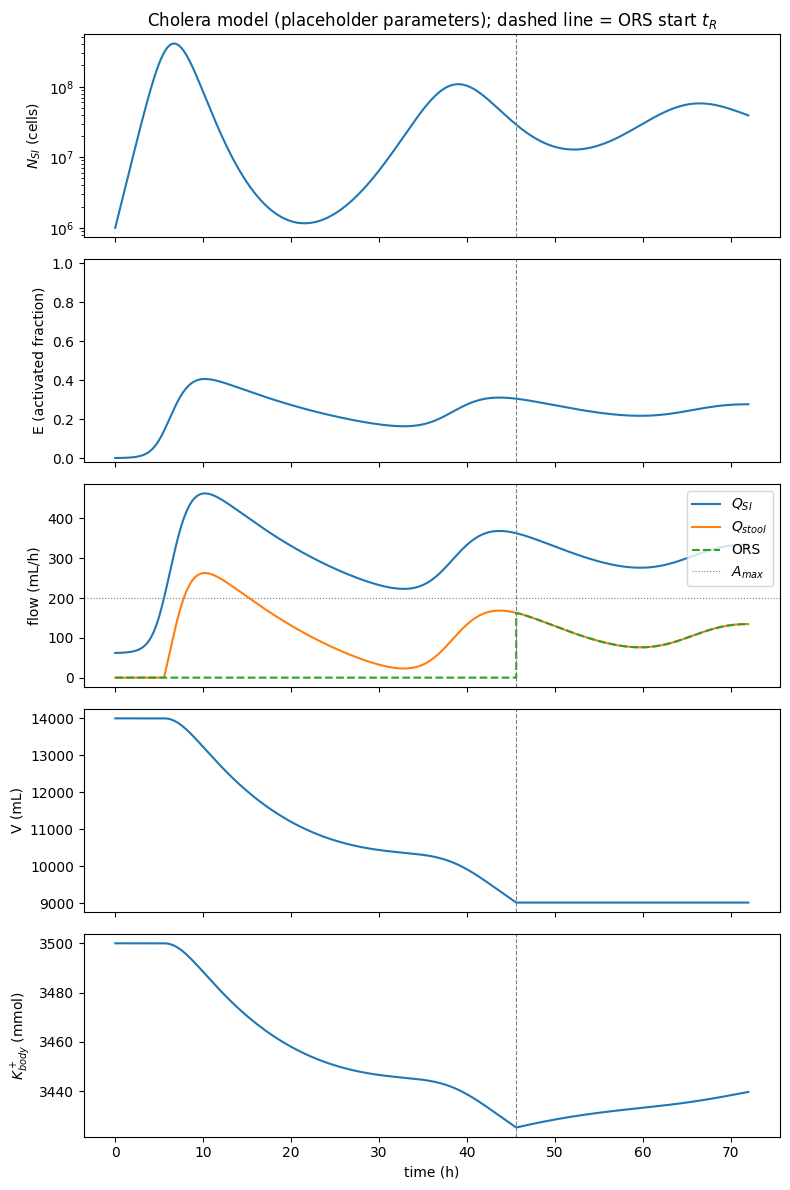

In [41]:
def timecourse(res, p):
    fig, axs = plt.subplots(5, 1, figsize=(8, 12), sharex=True)

    axs[0].semilogy(res.t, np.maximum(res.N_SI, 1e-3))
    axs[0].set_ylabel(r"$N_{SI}$ (cells)")

    axs[1].plot(res.t, res.E)
    axs[1].set_ylabel("E (activated fraction)")
    axs[1].set_ylim(-0.02, 1.02)

    axs[2].plot(res.t, res.Q_SI, label=r"$Q_{SI}$")
    axs[2].plot(res.t, res.Q_stool, label=r"$Q_{stool}$")
    axs[2].plot(res.t, res.ORS, "--", label="ORS")
    axs[2].axhline(p.A_max, color="gray", lw=0.8, ls=":", label=r"$A_{max}$")
    axs[2].set_ylabel("flow (mL/h)")
    axs[2].legend(loc="upper right")

    axs[3].plot(res.t, res.V)
    axs[3].set_ylabel("V (mL)")

    axs[4].plot(res.t, res.K)
    axs[4].set_ylabel(r"$K^+_{body}$ (mmol)")
    axs[4].set_xlabel("time (h)")

    for ax in axs:
        ax.axvline(p.t_R, color="gray", ls="--", lw=0.8)
    axs[0].set_title(r"Cholera model (placeholder parameters); dashed line = ORS start $t_R$")
    fig.tight_layout()
    return fig


fig = timecourse(res, p)

## 5. Sanity checks

Quick versions of the SPEC tests. Each cell prints `ok` or raises an `AssertionError`.

In [42]:
# Washout only: N_SI(t) = N0 * exp(-f_planktonic * Q_SI_0 / V_lumen * t)
q = p.with_(r_growth=0.0, k_imm=0.0, k_E_max=0.0)
r = simulate(q, t_end=10.0)
N0 = initial_state(q)[0]
analytic = N0 * np.exp(-q.f_planktonic * q.Q_SI_0 / q.V_lumen * r.t)
assert np.allclose(r.N_SI, analytic, rtol=1e-5), "washout-only does not match analytic"

# No bacteria: E stays 0; V and K stay at their initial values (Q_SI_0 <= A_max)
r = simulate(p.with_(N_intake=0.0))
assert np.all(r.E == 0) and np.allclose(r.V, p.V0) and np.allclose(r.K, p.K0)

# eta = 1: V constant after ORS starts
r = simulate(p.with_(eta=1.0))
after = r.t >= p.t_R
assert np.allclose(r.V[after], r.V[after][0], rtol=1e-6), "V not constant after t_R with eta=1"

# Bounds on the default run
assert res.E.min() >= -1e-9 and res.E.max() <= 1 + 1e-9 and res.N_SI.min() >= -1e-6

# Validation rejects bad inputs
for bad in (dict(eta=1.5), dict(V_lumen=0.0), dict(Q_SI_max=10.0)):
    try:
        p.with_(**bad)
    except ValueError:
        pass
    else:
        raise AssertionError(f"{bad} was accepted")

print("ok")

ok
